In [1]:
import empiricaldist
import janitor
import matplotlib.pyplot as plt
import numpy as np
import palmerpenguins
import pandas as pd
import scipy.stats
import seaborn as sns
import sklearn.metrics
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats as ss
import session_info

In [2]:
%matplotlib inline
sns.set_style(style='whitegrid')
sns.set_context(context='notebook')
plt.rcParams['figure.figsize'] = (11, 9.4)

penguin_color = {
    'Adelie': '#ff6602ff',
    'Gentoo': '#0f7175ff',
    'Chinstrap': '#c65dc9ff'
}

In [3]:
preprocessed_penguins_df = sns.load_dataset("penguins") #Datos preprocesados
processed_penguins_df= preprocessed_penguins_df.dropna()

In [14]:
model1= smf.ols(formula= "body_mass_g ~ bill_length_mm", data= processed_penguins_df).fit()
model1.summary()

model2= smf.ols(formula= "body_mass_g ~ bill_length_mm + bill_depth_mm", data= processed_penguins_df).fit()
model2.summary()

model3= smf.ols(formula= "body_mass_g ~ bill_length_mm + bill_depth_mm + flipper_length_mm", data= processed_penguins_df).fit()
model3.summary()

model4= smf.ols(formula= "body_mass_g ~ bill_length_mm + bill_depth_mm + flipper_length_mm + C(sex)", 
                data= processed_penguins_df).fit() #En los analisis de regresion multiple, se pueden incluir
# variables categoricas, solo debe ponerse asi: C("variable categorica")
model4.summary() 

model5= smf.ols(formula= "body_mass_g ~ flipper_length_mm", data= processed_penguins_df).fit()
model5.summary()

model6= smf.ols(formula= "body_mass_g ~ flipper_length_mm + C(sex)", data= processed_penguins_df).fit()
model6.summary() 

#NOTA: Hay que fijarse en el R-squared y analizar como cambia su valor, porque en ocasiones agregar mas variables 
# no necesariamente aumentan este estadistico de predictibilidad


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.805
Method:                 Least Squares   F-statistic:                     684.8
Date:                Wed, 20 Mar 2024   Prob (F-statistic):          3.53e-118
Time:                        11:16:14   Log-Likelihood:                -2427.2
No. Observations:                 333   AIC:                             4860.
Df Residuals:                     330   BIC:                             4872.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5410.3002    285.798    -18.931      0.000   -5972.515   -4848.085
C(sex)[T.Male]      347.8503     40.342      8.623      0.000     268.491     427.209
flipper_length_mm    46.9822      1.441     32.598      0.000      44.147      49.817
==============================================================================
Omnibus:                        0.262   Durbin-Watson:                   1.701
Prob(Omnibus):                  0.877   Jarque-Bera (JB):                0.376
Skew:                           0.051   Prob(JB):                        0.829
Kurtosis:                       2.870   Cond. No.                     2.95e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.95e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

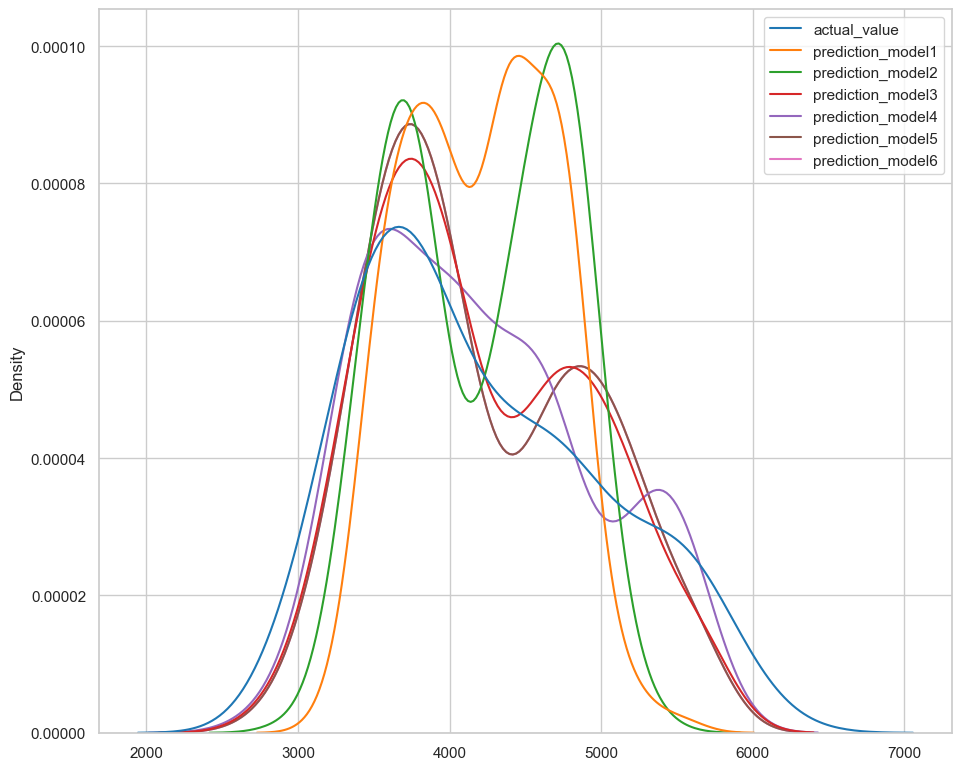

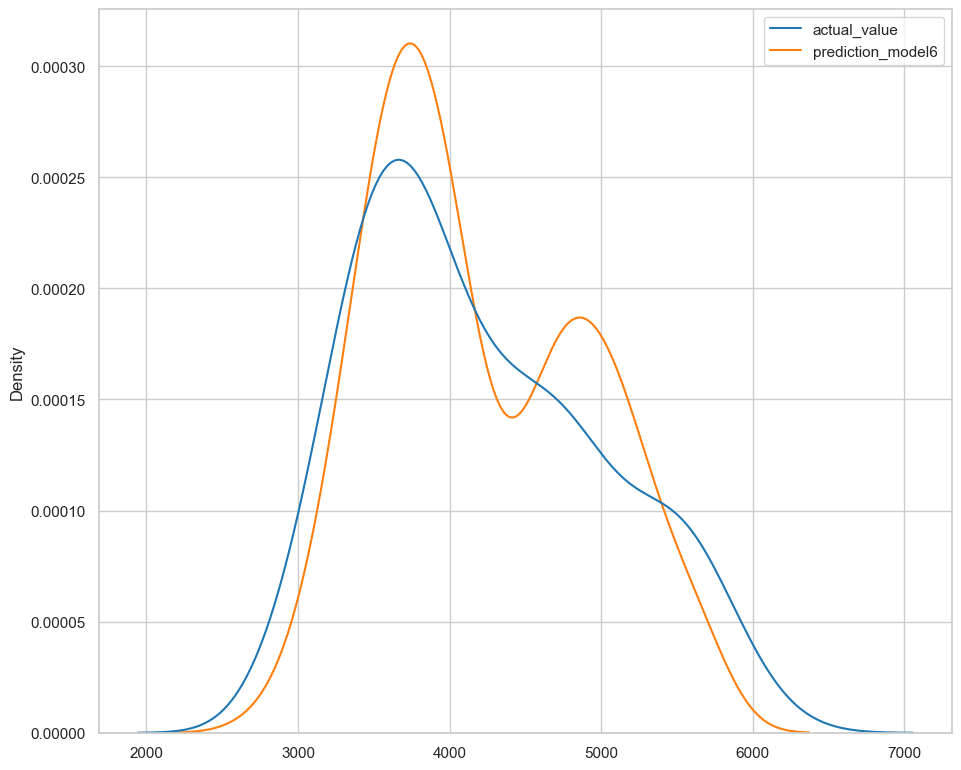

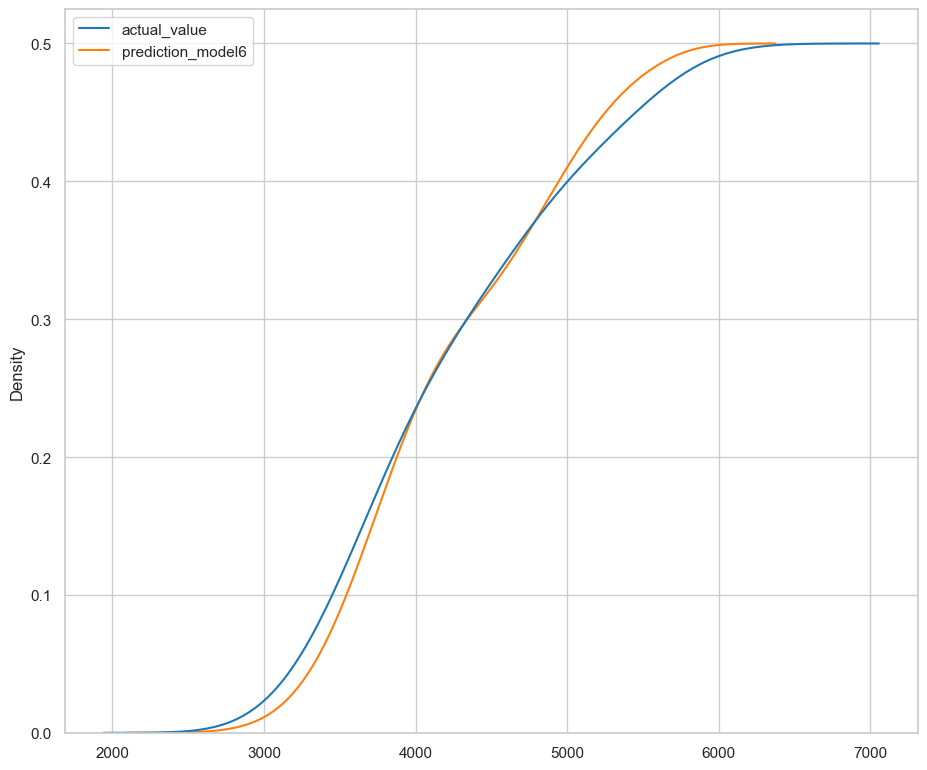

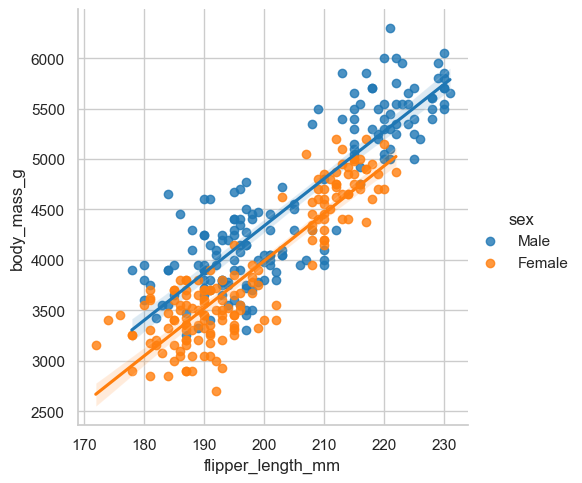

In [32]:
#VISUALIZAR LOS RESULTADOS

#Tabla de los resultados de prediccion de acuerdo al modelo
model_results = pd.DataFrame(
    dict(
        actual_value = processed_penguins_df.body_mass_g,
        prediction_model1= model1.predict(),
        prediction_model2= model2.predict(),
        prediction_model3= model3.predict(),
        prediction_model4= model4.predict(),
        prediction_model5= model5.predict(),
        prediction_model6= model6.predict(),
        species= processed_penguins_df.species,
        sex= processed_penguins_df.sex
    )
)

model_results


#Visualizar los modelos usando la Función de Distribución Empírica Acumulada (ECDFs)

#sns.ecdfplot(model_results) #Observar la prediccion de los modelos vs el valor real

#plt.figure()
#sns.ecdfplot(model_results.select_columns(["actual_value", "prediction_model6"])) #Seleccionar algunos modelos para observar la prediccion vs el valor real

#Visualizar los modelos usando la Función de Densidad de Probabilidad (PDFs)
plt.figure()
sns.kdeplot(model_results)

plt.figure()
sns.kdeplot(model_results.select_columns(["actual_value", "prediction_model6"]))

plt.figure()
sns.kdeplot(model_results.select_columns(["actual_value", "prediction_model6"]), cumulative= True) # "cumulative" es para ver los valores acumulados

sns.lmplot(processed_penguins_df, x= "flipper_length_mm", y= "body_mass_g", hue= "sex") #Visualizar la relacion entre las variables que mejor ajustan el modelo

Optimization terminated successfully.
         Current function value: 0.360900
         Iterations 7
-0.5273000000000001
Optimization terminated successfully.
         Current function value: 0.355225
         Iterations 8
   actual_adelie  predicted_values  count
0              0               0.0    151
1              1               1.0    129
2              0               1.0     36
3              1               0.0     17
[[151  36]
 [ 17 129]] 

 0.8408408408408409


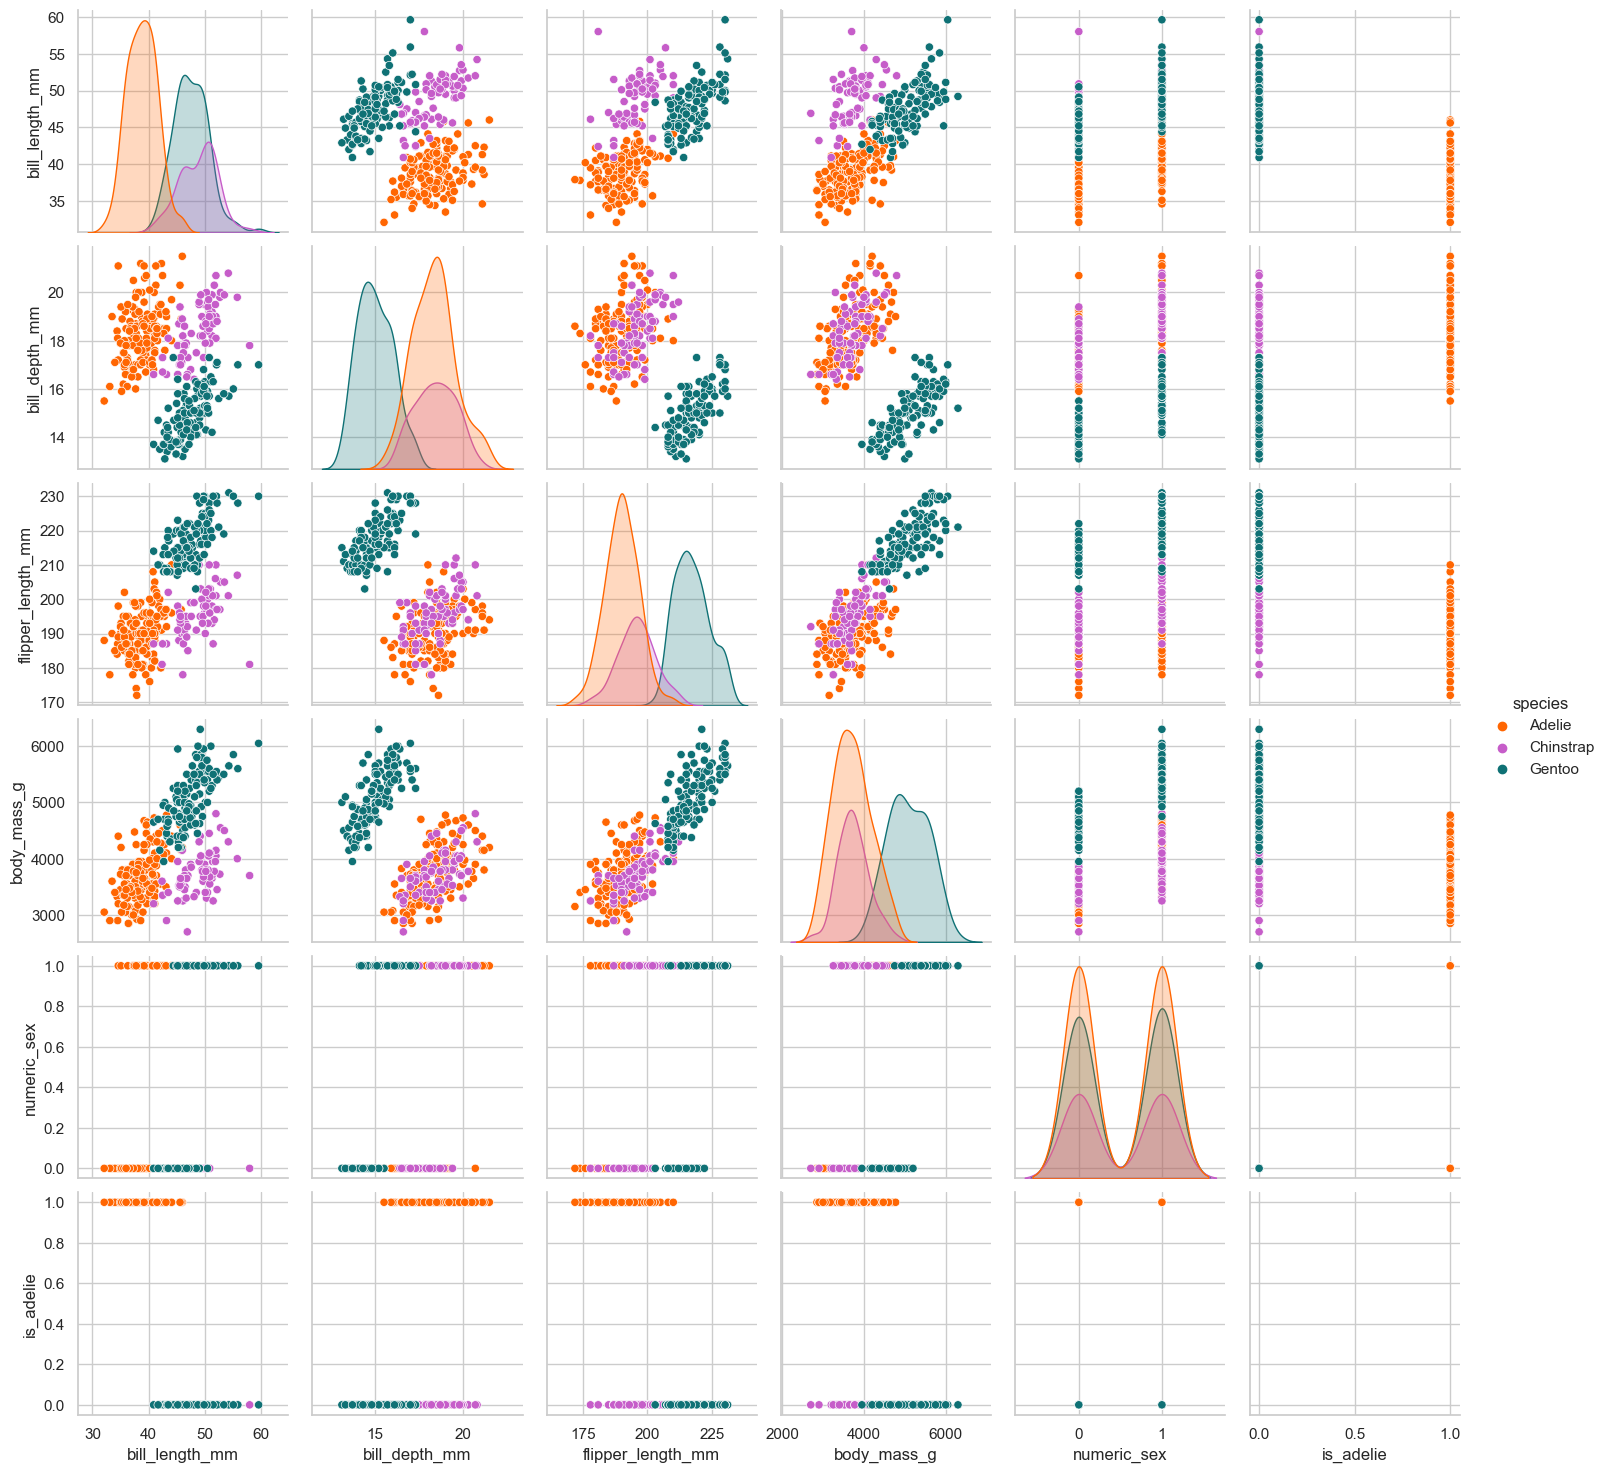

In [31]:
#REGRESION LOGISTICA

#Convertir el sexo en un numero
processed_penguins_df = (processed_penguins_df.assign(numeric_sex=lambda df: df.sex.replace(['Female', 'Male'], [0, 1])))

#Crear el modelo
smf.logit(formula= "numeric_sex ~ flipper_length_mm + bill_length_mm + bill_depth_mm + C(island)", data= processed_penguins_df).fit().summary()

#Para conocer la probabilidad de encontrar un pinguino macho en una de las islas, debo restar los coeficientes de los valores para las islas dadas por el modelo
island_Dream = -1.5596
island_Torgersen = -1.0323

probabilidad= island_Dream - island_Torgersen
print(probabilidad) #Segun el resultado, es mas probable encontrar pinguinos machos en la isla Dream que en Torgersen

#Modelo para identificar la especie del pinguino
#Vamos a tomar como referencia la especie Adelie, entonces, si es Adelie, es 1, sino, es 0
processed_penguins_df = (processed_penguins_df.assign(is_adelie=lambda df: df.species.replace(['Adelie', 'Chinstrap', 'Gentoo'], [1, 0, 0]))
)

model_is_adelie = smf.logit(formula='is_adelie ~ flipper_length_mm + C(sex)', data=processed_penguins_df).fit()
model_is_adelie.params

#Tabla de valores de las predicciones
is_adelie_df_predictions = pd.DataFrame(
    dict(
        actual_adelie = processed_penguins_df.is_adelie,
        predicted_values = model_is_adelie.predict().round() # "round" es para que me de los valores solo entre 0 y 1
    )
)

is_adelie_df_predictions

#Ver con mayor exactitud las predicciones
print(is_adelie_df_predictions.value_counts(["actual_adelie", "predicted_values"]).reset_index(name= "count")) 
#Interpretacion: 
# 151 pinguinos no adelie, fueron clasficados como no adelie
# 129 pinguinos adelie, fueron clasficados como adelie
# 36 pinguinos no adelie, fueron clasficados como adelie
# 17 pinguinos adelie, fueron clasficados como no adelie


#Crear la matriz de confusion y medir el rendimiento del modelo

confusion_matrix= sklearn.metrics.confusion_matrix(
    is_adelie_df_predictions.actual_adelie,
    is_adelie_df_predictions.predicted_values
)

accuracy= sklearn.metrics.accuracy_score(
    is_adelie_df_predictions.actual_adelie,
    is_adelie_df_predictions.predicted_values
)

print(confusion_matrix, "\n\n", accuracy) 

#Interpretacion: 
# 151 pinguinos no adelie, fueron clasficados como no adelie
# 129 pinguinos adelie, fueron clasficados como adelie
# 36 pinguinos no adelie, fueron clasficados como adelie
# 17 pinguinos adelie, fueron clasficados como no adelie

#El modelo precice un 84%

#Hacer un analisis exploratorio visual de todos los datos de acuerdo a la especie
sns.pairplot(processed_penguins_df, hue= "species", palette= penguin_color)